# PhonePe Pulse Case Study

**Overview:** PhonePe is one of India's largest digital payments platforms built on UPI. The PhonePe Pulse data captures how Indians transact digitally – how many transactions are made, of what type, for how much money, on which devices, and how many users are registered and active – across every state and district, quarter by quarter.

Analysing this data helps understand the growth of digital payments in India, which regions are adopting it faster, and how adoption relates to demographics such as population and population density.

## Dataset Details

All data is in one Excel file `phonepe.xlsx` with the following sheets:

| Sheet | Level | Contents |
|---|---|---|
| **State_Txn and Users** | State × Year × Quarter | Transactions, Amount (INR), ATV (INR), Registered Users, App Opens |
| **State_TxnSplit** | State × Year × Quarter × Transaction Type | Transactions, Amount (INR), ATV (INR) per transaction type |
| **State_DeviceData** | State × Year × Quarter × Brand | Registered Users and Percentage per device brand |
| **District_Txn and Users** | District × Year × Quarter | Transactions, Amount (INR), ATV (INR), Registered Users, App Opens per district |
| **District Demographics** | District | Headquarters, Population, Area (sq km), Density, Code |

*ATV = Average Transaction Value = Amount / Transactions.*

## Objective of the Case Study

- **Practical Application of Python:** Load multi-sheet Excel data and explore, clean, aggregate and merge it using Pandas.
- **Insightful Data Analysis:** Find which states and districts lead in digital payments, how usage changes over time, and which transaction types and device brands dominate.
- **Visualization:** Use Matplotlib to present trends, distributions and correlations.

## 1. Data Loading
Load each sheet of the Excel file into its own DataFrame and display a part of it.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# Load the Excel file
file_path = "phonepe.xlsx"

**Q1.1** Load the State_Txn and Users dataset and display its first 5 rows.

In [3]:
df_state_txn_users = pd.read_excel(file_path, sheet_name= "State_Txn and Users")

print("First 5 rows of State_Txn and Users dataset:")
df_state_txn_users.head()

First 5 rows of State_Txn and Users dataset:


,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,1.463176e+07,2197.621091,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,2.833854e+07,2498.989022,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,5.555747e+07,3415.768284,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,9.054834e+07,3811.277720,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,1.022997e+08,3355.630147,18596,0


**Q1.2** Load the State_TxnSplit dataset and display its bottom 10 rows.

In [4]:
df_state_txn_split = pd.read_excel(file_path, sheet_name= "State_TxnSplit")

print("Bottom 10 rows of State_TxnSplit dataset:")
df_state_txn_split.tail(10)

Bottom 10 rows of State_TxnSplit dataset:


,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
2504,West Bengal,2021,1,Peer-to-peer payments,53869075,2.022402e+11,3754.292226
2505,West Bengal,2021,1,Merchant payments,37143701,2.891834e+10,778.553104
2506,West Bengal,2021,1,Recharge & bill payments,26673733,1.133967e+10,425.124820
2507,West Bengal,2021,1,Financial Services,166727,1.754458e+08,1052.293941
2508,West Bengal,2021,1,Others,400816,2.635025e+08,657.415236
2509,West Bengal,2021,2,Peer-to-peer payments,64661051,2.308123e+11,3569.572026
2510,West Bengal,2021,2,Merchant payments,41696787,3.478787e+10,834.305703
2511,West Bengal,2021,2,Recharge & bill payments,34799709,1.333145e+10,383.090958
2512,West Bengal,2021,2,Financial Services,190537,1.864665e+08,978.636630
2513,West Bengal,2021,2,Others,549353,3.167447e+08,576.577748


**Q1.3** Load the State_DeviceData dataset and display 10 rows from the middle of the dataset.

In [5]:
df_state_device = pd.read_excel(file_path, sheet_name= "State_DeviceData")

# middle row index -> total rows // 2
middle_index = len(df_state_device) // 2

print("10 rows from the middle of State_DeviceData dataset:")
df_state_device.iloc[middle_index:middle_index + 10]

10 rows from the middle of State_DeviceData dataset:


,State,Year,Quarter,Brand,Registered Users,Percentage
2772,Lakshadweep,2018,1,Samsung,102,0.203593
2773,Lakshadweep,2018,1,Xiaomi,100,0.199601
2774,Lakshadweep,2018,1,Vivo,67,0.133733
2775,Lakshadweep,2018,1,Oppo,56,0.111776
2776,Lakshadweep,2018,1,Huawei,25,0.049900
2777,Lakshadweep,2018,1,OnePlus,22,0.043912
2778,Lakshadweep,2018,1,Apple,20,0.039920
2779,Lakshadweep,2018,1,Realme,20,0.039920
2780,Lakshadweep,2018,1,Gionee,12,0.023952
2781,Lakshadweep,2018,1,COOLPAD,10,0.019960


**Q1.4** Load the District_Txn and Users dataset and display its first 10 rows and last 10 rows.

In [6]:
df_district_txn_users = pd.read_excel(file_path, sheet_name= "District_Txn and Users")

print("First 10 rows of District_Txn and Users dataset:")
df_district_txn_users.head(10)

First 10 rows of District_Txn and Users dataset:


,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,Nicobars,AN01,528,1.139849e+06,2158.804548,262,0
1,Andaman & Nicobar Islands,2018,1,North And Middle Andaman,AN02,442,9.316631e+05,2107.835016,632,0
2,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,1.256025e+07,2208.201361,5846,0
3,Andaman & Nicobar Islands,2018,2,Nicobars,AN01,1120,3.072437e+06,2743.247239,351,0
4,Andaman & Nicobar Islands,2018,2,North And Middle Andaman,AN02,825,1.317863e+06,1597.409798,911,0
5,Andaman & Nicobar Islands,2018,2,South Andaman,AN03,9395,2.394824e+07,2549.040502,8143,0
6,Andaman & Nicobar Islands,2018,3,Nicobars,AN01,1471,6.387829e+06,4342.507921,467,0
7,Andaman & Nicobar Islands,2018,3,North And Middle Andaman,AN02,1283,4.901530e+06,3820.365954,1208,0
8,Andaman & Nicobar Islands,2018,3,South Andaman,AN03,13511,4.426811e+07,3276.449742,10474,0
9,Andaman & Nicobar Islands,2018,4,Nicobars,AN01,1485,7.180859e+06,4835.595525,536,0


In [7]:
print("Last 10 rows of District_Txn and Users dataset:")
df_district_txn_users.tail(10)

Last 10 rows of District_Txn and Users dataset:


,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
10238,West Bengal,2021,2,Murshidabad,WB14,8602251,1.999694e+10,2324.616616,1248602,16530655
10239,West Bengal,2021,2,Nadia,WB15,5524174,1.122758e+10,2032.445525,955428,13665885
10240,West Bengal,2021,2,North Twenty Four Parganas,WB16,17258291,3.041482e+10,1762.331031,2660664,37899453
10241,West Bengal,2021,2,Paschim Bardhaman,WB17,4893774,8.731263e+09,1784.157359,789026,10545670
10242,West Bengal,2021,2,Paschim Medinipur,WB18,5051834,1.030351e+10,2039.558976,856640,16201033
10243,West Bengal,2021,2,Purba Bardhaman,WB19,3920729,7.572502e+09,1931.401639,787970,12128849
10244,West Bengal,2021,2,Purba Medinipur,WB20,6418522,1.515507e+10,2361.146027,946277,15491958
10245,West Bengal,2021,2,Purulia,WB21,1895981,2.790996e+09,1472.059252,435131,8843358
10246,West Bengal,2021,2,South Twenty Four Parganas,WB22,6661813,1.339853e+10,2011.243709,1286588,19344293
10247,West Bengal,2021,2,Uttar Dinajpur,WB23,2253385,5.564221e+09,2469.272118,392388,8184990


**Q1.5** Load the District Demographics dataset and display every 10th row.

In [8]:
df_district_demographics = pd.read_excel(file_path, sheet_name= "District Demographics")

print("Every 10th row of District Demographics dataset:")
# [start:stop:step] -> step of 10
df_district_demographics.iloc[::10]

Every 10th row of District Demographics dataset:


,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
0,Andhra Pradesh,Anantapur,Anantapur,4083315,19130.0,213,AP01,Anantapur
10,Andhra Pradesh,Visakhapatnam,Visakhapatnam,4288113,11161.0,384,AP10,Visakhapatnam
20,Arunachal Pradesh,Lepa Rada,Basar,0,0.0,0,AR08,Lepa Rada
30,Arunachal Pradesh,Siang,Pangin,31920,2919.0,11,AR18,Siang
40,Assam,Barpeta,Barpeta,1693622,3245.0,520,AS03,Barpeta
...,...,...,...,...,...,...,...,...
700,Chandigarh,Chandigarh,Chandigarh,1055450,114.0,9258,CH01,Chandigarh
710,Jammu & Kashmir,Jammu,Jammu,1526406,3097.0,596,JK07,Jammu
720,Jammu & Kashmir,Samba,Samba,318611,913.0,318,JK17,Samba
730,Delhi,North Delhi,Sadar Bazaar,887978,59.0,14557,DL04,North


## 2. Data Exploration
**Q2.1** Display summary statistics for numerical columns in each dataset.

In [9]:
print("Summary statistics for State_Txn and Users dataset:")
df_state_txn_users.describe()

Summary statistics for State_Txn and Users dataset:


,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
count,504.000000,504.000000,5.040000e+02,5.030000e+02,504.000000,5.040000e+02,5.040000e+02
mean,2019.285714,2.357143,4.074000e+07,7.083332e+10,1993.471543,4.777501e+06,9.774471e+07
std,1.031181,1.109971,8.228714e+07,1.440902e+11,607.464894,6.644496e+06,2.042376e+08
min,2018.000000,1.000000,7.780000e+02,1.928611e+06,0.000000,5.010000e+02,0.000000e+00
25%,2018.000000,1.000000,5.925578e+05,1.167157e+09,1598.910667,1.574202e+05,0.000000e+00
50%,2019.000000,2.000000,6.217487e+06,1.051605e+10,1861.380589,1.747914e+06,2.930574e+06
75%,2020.000000,3.000000,4.363675e+07,6.947045e+10,2259.087924,7.320945e+06,8.615022e+07
max,2021.000000,4.000000,5.736165e+08,1.027958e+12,3938.733850,3.966470e+07,1.208084e+09


In [10]:
print("Summary statistics for State_TxnSplit dataset:")
df_state_txn_split.describe()

Summary statistics for State_TxnSplit dataset:


,Year,Quarter,Transactions,Amount (INR),ATV (INR)
count,2514.000000,2514.000000,2.514000e+03,2.514000e+03,2514.000000
mean,2019.286794,2.358393,8.167446e+06,1.443978e+10,1349.927929
std,1.030807,1.109251,2.423645e+07,5.995054e+10,1534.866221
min,2018.000000,1.000000,2.000000e+00,3.439721e+01,17.198606
25%,2018.000000,1.000000,2.788075e+04,1.762412e+07,385.735827
50%,2019.000000,2.000000,2.687980e+05,1.901189e+08,720.940406
75%,2020.000000,3.000000,3.683230e+06,2.661248e+09,1352.790116
max,2021.000000,4.000000,2.795990e+08,8.721520e+11,7767.539936


In [11]:
print("Summary statistics for State_DeviceData dataset:")
df_state_device.describe()

Summary statistics for State_DeviceData dataset:


,Year,Quarter,Registered Users,Percentage
count,5544.000000,5544.000000,5.544000e+03,5544.000000
mean,2019.285714,2.357143,4.343183e+05,0.090909
std,1.030250,1.108970,9.056069e+05,0.083095
min,2018.000000,1.000000,1.000000e+01,0.006373
25%,2018.000000,1.000000,8.055750e+03,0.021588
50%,2019.000000,2.000000,7.442250e+04,0.056914
75%,2020.000000,3.000000,3.978875e+05,0.143626
max,2021.000000,4.000000,9.764252e+06,0.478367


In [12]:
print("Summary statistics for District_Txn and Users dataset:")
df_district_txn_users.describe()

Summary statistics for District_Txn and Users dataset:


,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
count,10248.000000,10248.000000,1.024800e+04,1.024800e+04,10244.000000,1.024800e+04,1.024800e+04
mean,2019.285714,2.357143,2.003607e+06,3.542311e+09,1909.796545,2.349591e+05,4.807117e+06
std,1.030208,1.108924,9.613466e+06,1.473154e+10,600.943349,4.605978e+05,1.562541e+07
min,2018.000000,1.000000,0.000000e+00,0.000000e+00,84.944283,2.200000e+01,0.000000e+00
25%,2018.000000,1.000000,1.031418e+05,1.756668e+08,1554.589051,3.619550e+04,0.000000e+00
50%,2019.000000,2.000000,3.763065e+05,6.784562e+08,1863.135530,1.067640e+05,6.403025e+05
75%,2020.000000,3.000000,1.272815e+06,2.377256e+09,2203.083552,2.573165e+05,4.346320e+06
max,2021.000000,4.000000,3.487128e+08,4.444224e+11,11209.980550,1.060461e+07,5.544197e+08


In [13]:
print("Summary statistics for District Demographics dataset:")
df_district_demographics.describe()

Summary statistics for District Demographics dataset:


,Population,Area (sq km),Density
count,7.420000e+02,742.000000,742.000000
mean,1.668555e+06,4395.373120,838.512129
std,1.458849e+06,4254.676124,2754.406896
min,0.000000e+00,0.000000,0.000000
25%,6.530815e+05,2039.750000,198.000000
50%,1.322359e+06,3402.500000,353.000000
75%,2.297440e+06,5432.750000,686.250000
max,1.008285e+07,45652.000000,36155.000000


**Q2.2** Display the data types of each column in each dataset.

In [14]:
print("Data types for State_Txn and Users dataset:")
df_state_txn_users.dtypes

Data types for State_Txn and Users dataset:


State                   str
Year                  int64
Quarter               int64
Transactions          int64
Amount (INR)        float64
ATV (INR)           float64
Registered Users      int64
App Opens             int64
dtype: object

In [15]:
print("Data types for State_TxnSplit dataset:")
df_state_txn_split.dtypes

Data types for State_TxnSplit dataset:


State                   str
Year                  int64
Quarter               int64
Transaction Type        str
Transactions          int64
Amount (INR)        float64
ATV (INR)           float64
dtype: object

In [16]:
print("Data types for State_DeviceData dataset:")
df_state_device.dtypes

Data types for State_DeviceData dataset:


State                   str
Year                  int64
Quarter               int64
Brand                   str
Registered Users      int64
Percentage          float64
dtype: object

In [17]:
print("Data types for District_Txn and Users dataset:")
df_district_txn_users.dtypes

Data types for District_Txn and Users dataset:


State                   str
Year                  int64
Quarter               int64
District                str
Code                    str
Transactions          int64
Amount (INR)        float64
ATV (INR)           float64
Registered Users      int64
App Opens             int64
dtype: object

In [18]:
print("Data types for District Demographics dataset:")
df_district_demographics.dtypes

Data types for District Demographics dataset:


State                 str
District              str
Headquarters          str
Population          int64
Area (sq km)      float64
Density             int64
Code                  str
Alternate Name        str
dtype: object

## 3. Handling Missing Data
**Q3.1** Identify missing values in each dataset.

In [19]:
print("Missing values in State_Txn and Users dataset:")
df_state_txn_users.isnull().sum()

Missing values in State_Txn and Users dataset:


State               0
Year                0
Quarter             0
Transactions        0
Amount (INR)        1
ATV (INR)           0
Registered Users    0
App Opens           0
dtype: int64

In [20]:
print("Missing values in State_TxnSplit dataset:")
df_state_txn_split.isnull().sum()

Missing values in State_TxnSplit dataset:


State               0
Year                0
Quarter             0
Transaction Type    0
Transactions        0
Amount (INR)        0
ATV (INR)           0
dtype: int64

In [21]:
print("Missing values in State_DeviceData dataset:")
df_state_device.isnull().sum()

Missing values in State_DeviceData dataset:


State               0
Year                0
Quarter             0
Brand               0
Registered Users    0
Percentage          0
dtype: int64

In [22]:
print("Missing values in District_Txn and Users dataset:")
df_district_txn_users.isnull().sum()

Missing values in District_Txn and Users dataset:


State                0
Year                 0
Quarter              0
District             0
Code                28
Transactions         0
Amount (INR)         0
ATV (INR)            4
Registered Users     0
App Opens            0
dtype: int64

In [23]:
print("Missing values in District Demographics dataset:")
df_district_demographics.isnull().sum()

Missing values in District Demographics dataset:


State             0
District          0
Headquarters      0
Population        0
Area (sq km)      0
Density           0
Code              0
Alternate Name    0
dtype: int64

**Q3.2** Calculate the percentage of missing values for each column.

`isnull()` gives True/False, and the mean of True/False = fraction of True values → × 100 = percentage.

In [24]:
print("Percentage of missing values in State_Txn and Users dataset:")
df_state_txn_users.isnull().mean() * 100

Percentage of missing values in State_Txn and Users dataset:


State               0.000000
Year                0.000000
Quarter             0.000000
Transactions        0.000000
Amount (INR)        0.198413
ATV (INR)           0.000000
Registered Users    0.000000
App Opens           0.000000
dtype: float64

In [25]:
print("Percentage of missing values in State_TxnSplit dataset:")
df_state_txn_split.isnull().mean() * 100

Percentage of missing values in State_TxnSplit dataset:


State               0.0
Year                0.0
Quarter             0.0
Transaction Type    0.0
Transactions        0.0
Amount (INR)        0.0
ATV (INR)           0.0
dtype: float64

In [26]:
print("Percentage of missing values in State_DeviceData dataset:")
df_state_device.isnull().mean() * 100

Percentage of missing values in State_DeviceData dataset:


State               0.0
Year                0.0
Quarter             0.0
Brand               0.0
Registered Users    0.0
Percentage          0.0
dtype: float64

In [27]:
print("Percentage of missing values in District_Txn and Users dataset:")
df_district_txn_users.isnull().mean() * 100

Percentage of missing values in District_Txn and Users dataset:


State               0.000000
Year                0.000000
Quarter             0.000000
District            0.000000
Code                0.273224
Transactions        0.000000
Amount (INR)        0.000000
ATV (INR)           0.039032
Registered Users    0.000000
App Opens           0.000000
dtype: float64

In [28]:
print("Percentage of missing values in District Demographics dataset:")
df_district_demographics.isnull().mean() * 100

Percentage of missing values in District Demographics dataset:


State             0.0
District          0.0
Headquarters      0.0
Population        0.0
Area (sq km)      0.0
Density           0.0
Code              0.0
Alternate Name    0.0
dtype: float64

**Q3.3** Highlight the column with the highest percentage of missing values in each dataset.

In [29]:
print("Column with the highest percentage of missing values in State_Txn and Users dataset:")
print(df_state_txn_users.isnull().mean().idxmax(), ":", df_state_txn_users.isnull().mean().max() * 100)

Column with the highest percentage of missing values in State_Txn and Users dataset:
Amount (INR) : 0.1984126984126984


In [30]:
print("Column with the highest percentage of missing values in State_TxnSplit dataset:")
print(df_state_txn_split.isnull().mean().idxmax(), ":", df_state_txn_split.isnull().mean().max() * 100)

Column with the highest percentage of missing values in State_TxnSplit dataset:
State : 0.0


In [31]:
print("Column with the highest percentage of missing values in State_DeviceData dataset:")
print(df_state_device.isnull().mean().idxmax(), ":", df_state_device.isnull().mean().max() * 100)

Column with the highest percentage of missing values in State_DeviceData dataset:
State : 0.0


In [32]:
print("Column with the highest percentage of missing values in District_Txn and Users dataset:")
print(df_district_txn_users.isnull().mean().idxmax(), ":", df_district_txn_users.isnull().mean().max() * 100)

Column with the highest percentage of missing values in District_Txn and Users dataset:
Code : 0.273224043715847


In [33]:
print("Column with the highest percentage of missing values in District Demographics dataset:")
print(df_district_demographics.isnull().mean().idxmax(), ":", df_district_demographics.isnull().mean().max() * 100)

Column with the highest percentage of missing values in District Demographics dataset:
State : 0.0


**Observation (Q3):**
- **State_Txn and Users:** `Amount (INR)` has 1 missing value (~0.20%) → Andhra Pradesh, 2021 Q1.
- **District_Txn and Users:** `Code` has 28 missing values (~0.27%) and `ATV (INR)` has 4.
- **State_TxnSplit, State_DeviceData, District Demographics:** no missing values (`idxmax()` just returns the first column, `State`, with 0%).

## 4. States and Districts
**Q4.1** Calculate the total number of states and the total number of districts.

In [34]:
total_states = df_state_txn_users["State"].nunique()
total_districts = df_district_txn_users["District"].nunique()

print("Total number of states:", total_states)
print("Total number of districts:", total_districts)

Total number of states: 36
Total number of districts: 723


In [35]:
# Check -> district data has one row per district per quarter
df_district_txn_users[df_district_txn_users["State"] == "Uttar Pradesh"]

,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
8876,Uttar Pradesh,2018,1,Agra,UP01,298049,3.534776e+08,1185.971395,148387,0
8877,Uttar Pradesh,2018,1,Aligarh,UP02,194881,2.270555e+08,1165.098223,84375,0
8878,Uttar Pradesh,2018,1,Ambedkar Nagar,UP04,116711,8.881857e+07,761.012805,36853,0
8879,Uttar Pradesh,2018,1,Amethi,UP05,96408,8.653458e+07,897.587094,28949,0
8880,Uttar Pradesh,2018,1,Amroha,UP06,72415,7.652425e+07,1056.745858,27497,0
...,...,...,...,...,...,...,...,...,...,...
9921,Uttar Pradesh,2021,2,Sitapur,UP71,1217768,2.551043e+09,2094.851267,366017,8689425
9922,Uttar Pradesh,2021,2,Sonbhadra,UP72,1762236,3.894346e+09,2209.888802,252013,10775729
9923,Uttar Pradesh,2021,2,Sultanpur,UP73,1560506,3.446744e+09,2208.734756,278126,6392641
9924,Uttar Pradesh,2021,2,Unnao,UP74,1265296,2.629058e+09,2077.820277,271165,7660427


**Q4.2** Identify the state with the highest number of districts.

⚠️ In `District_Txn and Users` each district repeats once per quarter, so `value_counts()` counts **rows**, not districts. `District Demographics` has one row per district, so it gives the true district count.

In [36]:
# 1st WAY -> District_Txn and Users (counts rows = districts × quarters)
district_counts = df_district_txn_users["State"].value_counts()
district_counts

State
Uttar Pradesh                           1050
Madhya Pradesh                           728
Bihar                                    532
Tamil Nadu                               518
Maharashtra                              504
Assam                                    462
Gujarat                                  462
Rajasthan                                462
Telangana                                462
Karnataka                                420
Odisha                                   420
Chhattisgarh                             378
Arunachal Pradesh                        350
Jharkhand                                336
West Bengal                              322
Haryana                                  308
Jammu & Kashmir                          308
Punjab                                   308
Manipur                                  224
Kerala                                   196
Andhra Pradesh                           182
Uttarakhand                              182
Hima

In [37]:
state_with_most_districts = district_counts.idxmax()

print("State with the highest number of districts:", state_with_most_districts)
print("Number of districts in", state_with_most_districts, ":", district_counts.max())

State with the highest number of districts: Uttar Pradesh
Number of districts in Uttar Pradesh : 1050


In [38]:
# 2nd WAY -> District Demographics (one row per district)
district_counts = df_district_demographics["State"].value_counts()
district_counts

State
Uttar Pradesh                           75
Madhya Pradesh                          55
Bihar                                   38
Tamil Nadu                              38
Maharashtra                             36
Assam                                   34
Gujarat                                 33
Rajasthan                               33
Telangana                               33
Karnataka                               31
Odisha                                  30
Chhattisgarh                            28
Arunachal Pradesh                       25
Jharkhand                               24
Punjab                                  23
West Bengal                             23
Haryana                                 22
Jammu & Kashmir                         20
Manipur                                 16
Kerala                                  14
Andhra Pradesh                          13
Uttarakhand                             13
Himachal Pradesh                        12
Nagal

In [39]:
state_with_most_districts = district_counts.idxmax()

print("State with the highest number of districts:", state_with_most_districts)
print("Number of districts in", state_with_most_districts, ":", district_counts.max())

State with the highest number of districts: Uttar Pradesh
Number of districts in Uttar Pradesh : 75


## 5. Transaction Analysis
**Q5.1** Calculate the total number of transactions and total transaction amount for each state over the years.

In [40]:
df_state_txn_users

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,1.463176e+07,2197.621091,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,2.833854e+07,2498.989022,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,5.555747e+07,3415.768284,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,9.054834e+07,3811.277720,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,1.022997e+08,3355.630147,18596,0
...,...,...,...,...,...,...,...,...
499,West Bengal,2020,2,57676797,1.000994e+11,1735.523418,13222022,198589332
500,West Bengal,2020,3,79954504,1.568134e+11,1961.282329,14448366,246554831
501,West Bengal,2020,4,100340645,1.991655e+11,1984.893473,15662093,291721919
502,West Bengal,2021,1,118254052,2.429372e+11,2054.366877,16808799,316832674


In [41]:
df_state_txn_users["Year"] = df_state_txn_users["Year"].astype(str)

state_agg = df_state_txn_users.groupby(["State", "Year"]).agg({
    "Transactions": "sum",
    "Amount (INR)": "sum"
}).reset_index()

print("Total transactions and transaction amount for each state over the years:")
state_agg

Total transactions and transaction amount for each state over the years:


,State,Year,Transactions,Amount (INR)
0,Andaman & Nicobar Islands,2018,58021,1.890761e+08
1,Andaman & Nicobar Islands,2019,133104,4.734648e+08
2,Andaman & Nicobar Islands,2020,446274,1.296423e+09
3,Andaman & Nicobar Islands,2021,586166,1.682854e+09
4,Andhra Pradesh,2018,77779112,1.220720e+11
...,...,...,...,...
139,Uttarakhand,2021,44608834,7.727901e+10
140,West Bengal,2018,120011635,1.115887e+11
141,West Bengal,2019,257900590,2.660145e+11
142,West Bengal,2020,304222327,5.527316e+11


**Q5.2** Identify the top 5 states with the highest transaction volumes and the top 5 states with the lowest transaction volumes.

In [42]:
state_total_txn = df_state_txn_users.groupby("State")["Transactions"].sum().reset_index()
state_total_txn = state_total_txn.sort_values(by= "Transactions", ascending= False)

top_5_states_highest_txn = state_total_txn.head(5)

print("Top 5 states with the highest transaction volumes:")
top_5_states_highest_txn

Top 5 states with the highest transaction volumes:


,State,Transactions
15,Karnataka,2981044533
20,Maharashtra,2833670154
31,Telangana,2347430243
1,Andhra Pradesh,1781091169
28,Rajasthan,1382918930


In [43]:
top_5_states_lowest_txn = state_total_txn.tail(5)

print("Top 5 states with the lowest transaction volumes:")
top_5_states_lowest_txn

Top 5 states with the lowest transaction volumes:


,State,Transactions
22,Meghalaya,5648913
23,Mizoram,2162776
17,Ladakh,1880109
0,Andaman & Nicobar Islands,1223565
18,Lakshadweep,71610


**Observation (Q5.2):**
- **Highest volume:** Karnataka, Maharashtra, Telangana, Andhra Pradesh and Rajasthan – large, urbanised states with tech hubs (Bengaluru, Mumbai/Pune, Hyderabad).
- **Lowest volume:** Meghalaya, Mizoram, Ladakh, Andaman & Nicobar Islands and Lakshadweep – small population, remote regions with limited connectivity.

**Q5.3** Identify the most common transaction type in each state and quarter.

In [44]:
most_common_txn_type = df_state_txn_split.groupby(["State", "Year", "Quarter", "Transaction Type"]).agg({
    "Transactions": "sum"
}).reset_index()

most_common_txn_type

,State,Year,Quarter,Transaction Type,Transactions
0,Andaman & Nicobar Islands,2018,1,Financial Services,33
1,Andaman & Nicobar Islands,2018,1,Merchant payments,298
2,Andaman & Nicobar Islands,2018,1,Others,256
3,Andaman & Nicobar Islands,2018,1,Peer-to-peer payments,1871
4,Andaman & Nicobar Islands,2018,1,Recharge & bill payments,4200
...,...,...,...,...,...
2509,West Bengal,2021,2,Financial Services,190537
2510,West Bengal,2021,2,Merchant payments,41696787
2511,West Bengal,2021,2,Others,549353
2512,West Bengal,2021,2,Peer-to-peer payments,64661051


In [45]:
# idxmax() -> row index of the max Transactions within each (State, Year, Quarter) group
most_common_txn_type = most_common_txn_type.loc[most_common_txn_type.groupby(["State", "Year", "Quarter"])
                        ["Transactions"].idxmax()]

print("Most common transaction types in each state and quarter:")
most_common_txn_type

Most common transaction types in each state and quarter:


,State,Year,Quarter,Transaction Type,Transactions
4,Andaman & Nicobar Islands,2018,1,Recharge & bill payments,4200
9,Andaman & Nicobar Islands,2018,2,Recharge & bill payments,6735
14,Andaman & Nicobar Islands,2018,3,Recharge & bill payments,8636
19,Andaman & Nicobar Islands,2018,4,Recharge & bill payments,11517
24,Andaman & Nicobar Islands,2019,1,Recharge & bill payments,15263
...,...,...,...,...,...
2492,West Bengal,2020,2,Peer-to-peer payments,24855687
2497,West Bengal,2020,3,Peer-to-peer payments,37556349
2502,West Bengal,2020,4,Peer-to-peer payments,46437233
2507,West Bengal,2021,1,Peer-to-peer payments,53869075


In [46]:
# How often is each type the most common?
most_common_txn_type["Transaction Type"].value_counts()

Transaction Type
Peer-to-peer payments       311
Recharge & bill payments    162
Merchant payments            31
Name: count, dtype: int64

**Observation (Q5.3):** Out of 504 state-quarters, **Peer-to-peer payments** are the most common type in 311, **Recharge & bill payments** in 162 (mostly in the early quarters / smaller states) and **Merchant payments** in 31 (growing in recent quarters as shops adopt UPI QR codes).

## 6. Device Analysis
**Q6.1** Determine the device brand with the highest number of registered users in each state.

In [47]:
most_common_device_brand = df_state_device.groupby(["State", "Brand"]).agg({
    "Registered Users": "sum"
}).reset_index()

most_common_device_brand

,State,Brand,Registered Users
0,Andaman & Nicobar Islands,Apple,9334
1,Andaman & Nicobar Islands,Huawei,11497
2,Andaman & Nicobar Islands,Lenovo,5362
3,Andaman & Nicobar Islands,Motorola,9491
4,Andaman & Nicobar Islands,OnePlus,15397
...,...,...,...
443,West Bengal,Others,17526532
444,West Bengal,Realme,9322038
445,West Bengal,Samsung,30516315
446,West Bengal,Vivo,18755122


In [48]:
most_common_device_brand = most_common_device_brand.loc[most_common_device_brand.groupby("State")
                            ["Registered Users"].idxmax()]

print("Device brand with the highest number of registered users in each state:")
most_common_device_brand

Device brand with the highest number of registered users in each state:


,State,Brand,Registered Users
11,Andaman & Nicobar Islands,Xiaomi,97889
22,Andhra Pradesh,Xiaomi,40061549
34,Arunachal Pradesh,Xiaomi,437803
46,Assam,Xiaomi,6979357
60,Bihar,Xiaomi,33721314
73,Chandigarh,Xiaomi,896628
85,Chhattisgarh,Xiaomi,8763373
98,Dadra & Nagar Haveli and Daman & Diu,Xiaomi,638834
109,Delhi,Xiaomi,24114984
120,Goa,Xiaomi,1208672


In [49]:
most_common_device_brand["Brand"].value_counts()

Brand
Xiaomi     35
Samsung     1
Name: count, dtype: int64

**Observation (Q6.1):** **Xiaomi** has the most registered users in **35 of 36** states; **Samsung** leads in only 1. This reflects Xiaomi's strong position in India's budget smartphone market.

## 7. Demographic Analysis
**Q7.1** Identify the district with the highest population for each state and create a column chart.

In [50]:
top_districts_population = df_district_demographics.loc[df_district_demographics.groupby("State")
                            ["Population"].idxmax(), ["State", "District", "Population"]]

print("District with the highest population for each state:")
top_districts_population = top_districts_population.sort_values(by= "Population", ascending= False)
top_districts_population

District with the highest population for each state:


,State,District,Population
691,West Bengal,North 24 Parganas,10082852
235,Karnataka,Bangalore Urban,9588910
356,Maharashtra,Pune,9426959
140,Gujarat,Ahmedabad,7208200
509,Tamil Nadu,Chennai,7139882
489,Rajasthan,Jaipur,6663971
588,Uttar Pradesh,Allahabad,5959798
97,Bihar,Patna,5772804
2,Andhra Pradesh,East Godavari,5151549
270,Kerala,Malappuram,4110956


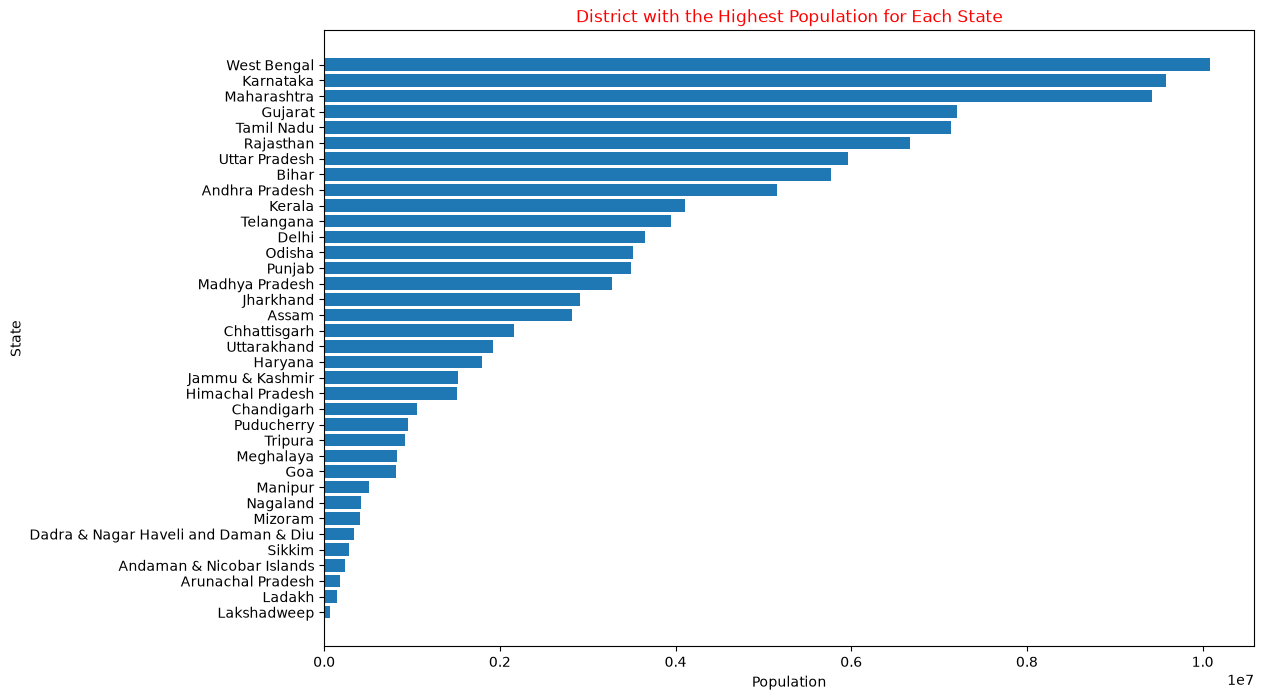

In [51]:
# Column chart -> district with the highest population for each state
plt.figure(figsize=(12, 8))
plt.barh(top_districts_population["State"], top_districts_population["Population"])
plt.xlabel("Population")
plt.ylabel("State")
plt.title("District with the Highest Population for Each State", color= "red")
plt.gca().invert_yaxis()   # largest on top
plt.show()

## 8. Average Transaction Value (ATV)
**Q8.1** Compute the average transaction value for each state.

In [52]:
state_atv = df_state_txn_users.groupby("State").agg({
    "ATV (INR)": "mean"
}).reset_index()

print("Average transaction value (ATV) for each state:")
state_atv

Average transaction value (ATV) for each state:


,State,ATV (INR)
0,Andaman & Nicobar Islands,3159.266422
1,Andhra Pradesh,1748.091476
2,Arunachal Pradesh,2638.323985
3,Assam,2008.495656
4,Bihar,2023.316978
5,Chandigarh,2113.797075
6,Chhattisgarh,1650.818617
7,Dadra & Nagar Haveli and Daman & Diu,1487.395599
8,Delhi,1589.839307
9,Goa,1895.258549


**Q8.2** Identify the top 5 states with the highest ATV and the top 5 states with the lowest ATV.

In [53]:
state_atv_sorted = state_atv.sort_values(by= "ATV (INR)", ascending= False)

top_5_states_highest_atv = state_atv_sorted.head(5)

print("Top 5 states with the highest average transaction value (ATV):")
top_5_states_highest_atv

Top 5 states with the highest average transaction value (ATV):


,State,ATV (INR)
17,Ladakh,3408.222984
0,Andaman & Nicobar Islands,3159.266422
23,Mizoram,2927.517802
18,Lakshadweep,2776.118701
2,Arunachal Pradesh,2638.323985


In [54]:
top_5_states_lowest_atv = state_atv_sorted.tail(5)

print("Top 5 states with the lowest average transaction value (ATV):")
top_5_states_lowest_atv

Top 5 states with the lowest average transaction value (ATV):


,State,ATV (INR)
15,Karnataka,1517.392249
20,Maharashtra,1516.361820
7,Dadra & Nagar Haveli and Daman & Diu,1487.395599
25,Odisha,1428.137367
35,West Bengal,1373.600590


**Observation (Q8.2):**
- **Highest ATV:** Ladakh (~₹3,408), Andaman & Nicobar Islands, Mizoram, Lakshadweep, Arunachal Pradesh – fewer but larger transactions (remote regions use digital payments mainly for bigger transfers).
- **Lowest ATV:** Karnataka, Maharashtra, Dadra & Nagar Haveli and Daman & Diu, Odisha, West Bengal (~₹1,374) – many small everyday payments (tea, groceries, travel), which brings the average down.
- Interesting: the states with the **highest volume** (Karnataka, Maharashtra) have among the **lowest ATV**.

## 9. App Usage Trends
**Q9.1** Calculate the total number of app opens over the years and quarters for each state.

In [55]:
app_opens_trend = df_state_txn_users.groupby(["State", "Year", "Quarter"]).agg({
    "App Opens": "sum"
}).reset_index()

print("Total number of app opens over the years and quarters for each state:")
app_opens_trend

Total number of app opens over the years and quarters for each state:


,State,Year,Quarter,App Opens
0,Andaman & Nicobar Islands,2018,1,0
1,Andaman & Nicobar Islands,2018,2,0
2,Andaman & Nicobar Islands,2018,3,0
3,Andaman & Nicobar Islands,2018,4,0
4,Andaman & Nicobar Islands,2019,1,0
...,...,...,...,...
499,West Bengal,2020,2,198589332
500,West Bengal,2020,3,246554831
501,West Bengal,2020,4,291721919
502,West Bengal,2021,1,316832674


**Q9.2** Identify trends in app usage by creating a line plot showing the number of app opens over time for Gujarat.

In [56]:
# Select a state for visualization
selected_state = "Gujarat"

# Filter data for the selected state
app_opens_selected_state = app_opens_trend[app_opens_trend["State"] == selected_state].copy()
app_opens_selected_state

,State,Year,Quarter,App Opens
140,Gujarat,2018,1,0
141,Gujarat,2018,2,0
142,Gujarat,2018,3,0
143,Gujarat,2018,4,0
144,Gujarat,2019,1,0
145,Gujarat,2019,2,34890301
146,Gujarat,2019,3,129441484
147,Gujarat,2019,4,147973757
148,Gujarat,2020,1,165605122
149,Gujarat,2020,2,155264359


In [57]:
# Combine Year and Quarter into one label for the x-axis -> "2018 Q1"
app_opens_selected_state["Year_Quarter"] = (
    app_opens_selected_state["Year"].astype(str)
    + " Q" +
    app_opens_selected_state["Quarter"].astype(str)
)
app_opens_selected_state

,State,Year,Quarter,App Opens,Year_Quarter
140,Gujarat,2018,1,0,2018 Q1
141,Gujarat,2018,2,0,2018 Q2
142,Gujarat,2018,3,0,2018 Q3
143,Gujarat,2018,4,0,2018 Q4
144,Gujarat,2019,1,0,2019 Q1
145,Gujarat,2019,2,34890301,2019 Q2
146,Gujarat,2019,3,129441484,2019 Q3
147,Gujarat,2019,4,147973757,2019 Q4
148,Gujarat,2020,1,165605122,2020 Q1
149,Gujarat,2020,2,155264359,2020 Q2


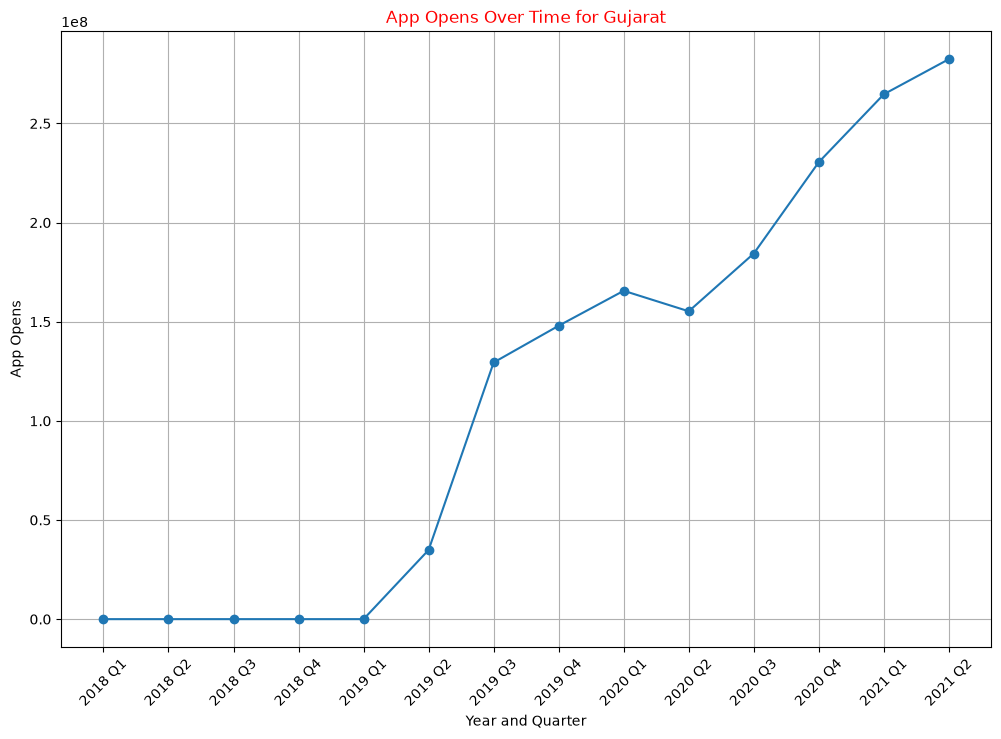

In [58]:
plt.figure(figsize=(12, 8))
plt.plot(app_opens_selected_state["Year_Quarter"], app_opens_selected_state["App Opens"], marker= "o")
plt.xlabel("Year and Quarter")
plt.ylabel("App Opens")
plt.title(f"App Opens Over Time for {selected_state}", color= "red")
plt.xticks(rotation=45)
plt.grid(True)
plt.show()

**Observation (Q9.2):** App Opens for Gujarat are **0 until 2019 Q1** (the metric was not reported before 2019 Q2). After that they grow steadily from ~3.5 crore to ~28 crore in 2021 Q2, with only a small dip in 2020 Q2 (COVID lockdown).

## 10. Transaction Type Distribution
**Q10.1** Create a bar chart showing the distribution of different transaction types for the most recent quarter in the dataset.

In [59]:
# Latest (Year, Quarter) pair
most_recent_quarter = (
    df_state_txn_split[["Year", "Quarter"]].drop_duplicates().nlargest(1, ["Year", "Quarter"]).iloc[0]
)
most_recent_quarter

Year       2021
Quarter       2
Name: 65, dtype: int64

In [60]:
most_recent_txn_types = (
    df_state_txn_split[(df_state_txn_split["Year"] == most_recent_quarter["Year"])
    & (df_state_txn_split["Quarter"] == most_recent_quarter["Quarter"])]
)
most_recent_txn_types

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
65,Andaman & Nicobar Islands,2021,2,Peer-to-peer payments,132772,7.483820e+08,5636.595402
66,Andaman & Nicobar Islands,2021,2,Recharge & bill payments,120911,4.369196e+07,361.356380
67,Andaman & Nicobar Islands,2021,2,Merchant payments,85143,1.037074e+08,1218.037989
68,Andaman & Nicobar Islands,2021,2,Financial Services,960,2.038522e+06,2123.459910
69,Andaman & Nicobar Islands,2021,2,Others,1628,1.327080e+06,815.159740
...,...,...,...,...,...,...,...
2509,West Bengal,2021,2,Peer-to-peer payments,64661051,2.308123e+11,3569.572026
2510,West Bengal,2021,2,Merchant payments,41696787,3.478787e+10,834.305703
2511,West Bengal,2021,2,Recharge & bill payments,34799709,1.333145e+10,383.090958
2512,West Bengal,2021,2,Financial Services,190537,1.864665e+08,978.636630


In [61]:
txn_type_distribution = most_recent_txn_types.groupby("Transaction Type").agg({
    "Transactions": "sum"
}).reset_index().sort_values(by= "Transactions", ascending= False)

txn_type_distribution

,Transaction Type,Transactions
3,Peer-to-peer payments,1744265068
1,Merchant payments,1499624295
4,Recharge & bill payments,685022045
2,Others,9061701
0,Financial Services,3397356


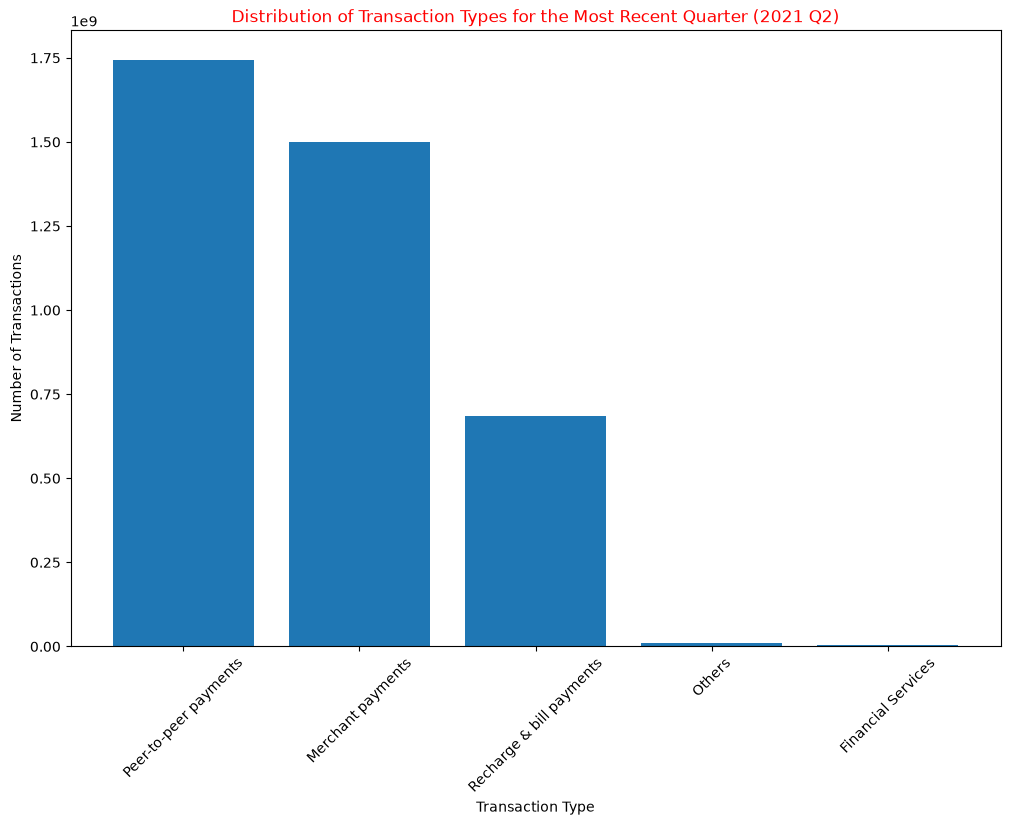

In [62]:
plt.figure(figsize=(12, 8))
plt.bar(txn_type_distribution["Transaction Type"], txn_type_distribution["Transactions"])
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.title(f"Distribution of Transaction Types for the Most Recent Quarter ({most_recent_quarter['Year']} Q{most_recent_quarter['Quarter']})", color= "red")
plt.xticks(rotation=45)
plt.show()

## 11. District Code Mapping
**Q11.1** Identify the unique mapping between district names and district codes, and create a CSV file containing it.

In [63]:
unique_district_mapping = df_district_txn_users[["District", "Code"]].drop_duplicates()

print("Unique mapping between district names and district codes:")
unique_district_mapping

Unique mapping between district names and district codes:


,District,Code
0,Nicobars,AN01
1,North And Middle Andaman,AN02
2,South Andaman,AN03
42,Anantapur,AP01
43,Chittoor,AP02
...,...,...
9944,Purba Bardhaman,WB19
9945,Purba Medinipur,WB20
9946,Purulia,WB21
9947,South Twenty Four Parganas,WB22


In [64]:
# Create a CSV file containing the unique district name and district code mappings
unique_district_mapping.to_csv("unique_district_mapping.csv", index= False)
print("CSV file 'unique_district_mapping.csv' created successfully.")

CSV file 'unique_district_mapping.csv' created successfully.


## 12. Data Consistency Check (District vs State)
**Q12.1** Calculate the total transactions, total transaction amount and total registered users by summing up the district level data, and compare them with the state level data.

In [65]:
district_agg = df_district_txn_users.groupby("State").agg({
    "Transactions": "sum",
    "Amount (INR)": "sum",
    "Registered Users": "sum"
}).reset_index()

print("Aggregated values at the district level:")
district_agg

Aggregated values at the district level:


,State,Transactions,Amount (INR),Registered Users
0,Andaman & Nicobar Islands,1223565,3.641818e+09,408396
1,Andhra Pradesh,1781091169,3.860292e+12,158007957
2,Arunachal Pradesh,8043799,2.225183e+10,1862214
3,Assam,123577981,2.814087e+11,26860751
4,Bihar,713643889,1.639579e+12,115284760
5,Chandigarh,25516542,5.371208e+10,3801466
6,Chhattisgarh,241908549,4.156353e+11,37448388
7,Dadra & Nagar Haveli and Daman & Diu,12462185,1.865878e+10,2701112
8,Delhi,1011031124,1.649942e+12,95374654
9,Goa,24481604,4.427187e+10,4755320


In [66]:
state_agg = df_state_txn_users.groupby("State").agg({
    "Transactions": "sum",
    "Amount (INR)": "sum",
    "Registered Users": "sum"
}).reset_index()

state_agg

,State,Transactions,Amount (INR),Registered Users
0,Andaman & Nicobar Islands,1223565,3.641818e+09,408396
1,Andhra Pradesh,1781091169,3.187847e+12,158007957
2,Arunachal Pradesh,8043799,2.225183e+10,1862214
3,Assam,123577981,2.814087e+11,26860751
4,Bihar,713643889,1.639579e+12,115284760
5,Chandigarh,25516542,5.371208e+10,3801466
6,Chhattisgarh,241908549,4.156353e+11,37448388
7,Dadra & Nagar Haveli and Daman & Diu,12462185,1.865878e+10,2701112
8,Delhi,1011031124,1.649942e+12,95374654
9,Goa,24481604,4.427187e+10,4755320


In [67]:
comparison = pd.merge(state_agg, district_agg, on= "State", suffixes= ("_state", "_district"))

comparison

,State,Transactions_state,Amount (INR)_state,Registered Users_state,Transactions_district,Amount (INR)_district,Registered Users_district
0,Andaman & Nicobar Islands,1223565,3.641818e+09,408396,1223565,3.641818e+09,408396
1,Andhra Pradesh,1781091169,3.187847e+12,158007957,1781091169,3.860292e+12,158007957
2,Arunachal Pradesh,8043799,2.225183e+10,1862214,8043799,2.225183e+10,1862214
3,Assam,123577981,2.814087e+11,26860751,123577981,2.814087e+11,26860751
4,Bihar,713643889,1.639579e+12,115284760,713643889,1.639579e+12,115284760
5,Chandigarh,25516542,5.371208e+10,3801466,25516542,5.371208e+10,3801466
6,Chhattisgarh,241908549,4.156353e+11,37448388,241908549,4.156353e+11,37448388
7,Dadra & Nagar Haveli and Daman & Diu,12462185,1.865878e+10,2701112,12462185,1.865878e+10,2701112
8,Delhi,1011031124,1.649942e+12,95374654,1011031124,1.649942e+12,95374654
9,Goa,24481604,4.427187e+10,4755320,24481604,4.427187e+10,4755320


In [68]:
# Check for discrepancies
comparison["Transactions_Match"] = comparison["Transactions_state"] == comparison["Transactions_district"]
comparison["Amount_Match"] = comparison["Amount (INR)_state"] == comparison["Amount (INR)_district"]
comparison["Users_Match"] = comparison["Registered Users_state"] == comparison["Registered Users_district"]

comparison

,State,Transactions_state,Amount (INR)_state,Registered Users_state,Transactions_district,Amount (INR)_district,Registered Users_district,Transactions_Match,Amount_Match,Users_Match
0,Andaman & Nicobar Islands,1223565,3.641818e+09,408396,1223565,3.641818e+09,408396,True,False,True
1,Andhra Pradesh,1781091169,3.187847e+12,158007957,1781091169,3.860292e+12,158007957,True,False,True
2,Arunachal Pradesh,8043799,2.225183e+10,1862214,8043799,2.225183e+10,1862214,True,False,True
3,Assam,123577981,2.814087e+11,26860751,123577981,2.814087e+11,26860751,True,False,True
4,Bihar,713643889,1.639579e+12,115284760,713643889,1.639579e+12,115284760,True,False,True
5,Chandigarh,25516542,5.371208e+10,3801466,25516542,5.371208e+10,3801466,True,False,True
6,Chhattisgarh,241908549,4.156353e+11,37448388,241908549,4.156353e+11,37448388,True,False,True
7,Dadra & Nagar Haveli and Daman & Diu,12462185,1.865878e+10,2701112,12462185,1.865878e+10,2701112,True,False,True
8,Delhi,1011031124,1.649942e+12,95374654,1011031124,1.649942e+12,95374654,True,False,True
9,Goa,24481604,4.427187e+10,4755320,24481604,4.427187e+10,4755320,True,False,True


In [69]:
# Display discrepancies
discrepancies = comparison[(comparison["Transactions_Match"] == False) | (comparison["Amount_Match"] == False) | (comparison["Users_Match"] == False)]

print("Discrepancies found between district-level and state-level data:")
discrepancies

Discrepancies found between district-level and state-level data:


,State,Transactions_state,Amount (INR)_state,Registered Users_state,Transactions_district,Amount (INR)_district,Registered Users_district,Transactions_Match,Amount_Match,Users_Match
0,Andaman & Nicobar Islands,1223565,3.641818e+09,408396,1223565,3.641818e+09,408396,True,False,True
1,Andhra Pradesh,1781091169,3.187847e+12,158007957,1781091169,3.860292e+12,158007957,True,False,True
2,Arunachal Pradesh,8043799,2.225183e+10,1862214,8043799,2.225183e+10,1862214,True,False,True
3,Assam,123577981,2.814087e+11,26860751,123577981,2.814087e+11,26860751,True,False,True
4,Bihar,713643889,1.639579e+12,115284760,713643889,1.639579e+12,115284760,True,False,True
5,Chandigarh,25516542,5.371208e+10,3801466,25516542,5.371208e+10,3801466,True,False,True
6,Chhattisgarh,241908549,4.156353e+11,37448388,241908549,4.156353e+11,37448388,True,False,True
7,Dadra & Nagar Haveli and Daman & Diu,12462185,1.865878e+10,2701112,12462185,1.865878e+10,2701112,True,False,True
8,Delhi,1011031124,1.649942e+12,95374654,1011031124,1.649942e+12,95374654,True,False,True
9,Goa,24481604,4.427187e+10,4755320,24481604,4.427187e+10,4755320,True,False,True


In [70]:
# Amounts are decimals (float) -> summing in a different order gives tiny differences.
# Compare with a tolerance of 1 rupee instead of exact ==
comparison["Amount_Match_Rounded"] = (comparison["Amount (INR)_state"] - comparison["Amount (INR)_district"]).abs() < 1

comparison[comparison["Amount_Match_Rounded"] == False]

,State,Transactions_state,Amount (INR)_state,Registered Users_state,Transactions_district,Amount (INR)_district,Registered Users_district,Transactions_Match,Amount_Match,Users_Match,Amount_Match_Rounded
1,Andhra Pradesh,1781091169,3.187847e+12,158007957,1781091169,3.860292e+12,158007957,True,False,True,False


In [71]:
# Reason -> the state level Amount is missing for this quarter
df_state_txn_users[df_state_txn_users["Amount (INR)"].isnull()]

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
26,Andhra Pradesh,2021,1,289747970,NaN,0.0,18363733,957709447


**Observation (Q12):**
- **Transactions** and **Registered Users** match exactly for every state.
- With exact `==`, **Amount** looks mismatched for almost every state, but that is only floating point rounding.
- With a ₹1 tolerance, only **Andhra Pradesh** mismatches, because its state level `Amount (INR)` for **2021 Q1 is missing** (seen in the missing value check).

## 13. Registered Users vs Population
**Q13.1** Merge the State_Txn and Users dataset with the District Demographics dataset and calculate the ratio of registered users to the population for each state.

In [72]:
# State population = sum of its district populations
state_population = df_district_demographics.groupby("State").agg({
    "Population": "sum"
}).reset_index()

state_population

,State,Population
0,Andaman & Nicobar Islands,380581
1,Andhra Pradesh,49378776
2,Arunachal Pradesh,1606047
3,Assam,34461385
4,Bihar,103817951
5,Chandigarh,1055450
6,Chhattisgarh,25867958
7,Dadra & Nagar Haveli and Daman & Diu,586956
8,Delhi,16787941
9,Goa,1457723


In [73]:
state_users_population = pd.merge(df_state_txn_users.groupby("State").agg({
    "Registered Users": "sum"
}).reset_index(), state_population, on= "State")

state_users_population

,State,Registered Users,Population
0,Andaman & Nicobar Islands,408396,380581
1,Andhra Pradesh,158007957,49378776
2,Arunachal Pradesh,1862214,1606047
3,Assam,26860751,34461385
4,Bihar,115284760,103817951
5,Chandigarh,3801466,1055450
6,Chhattisgarh,37448388,25867958
7,Dadra & Nagar Haveli and Daman & Diu,2701112,586956
8,Delhi,95374654,16787941
9,Goa,4755320,1457723


In [74]:
state_users_population["Users_to_Population_Ratio"] = (
                    state_users_population["Registered Users"] / state_users_population["Population"]
)
print("Ratio of registered users to population for each state:")
state_users_population

Ratio of registered users to population for each state:


,State,Registered Users,Population,Users_to_Population_Ratio
0,Andaman & Nicobar Islands,408396,380581,1.073086
1,Andhra Pradesh,158007957,49378776,3.199916
2,Arunachal Pradesh,1862214,1606047,1.159502
3,Assam,26860751,34461385,0.779445
4,Bihar,115284760,103817951,1.110451
5,Chandigarh,3801466,1055450,3.601749
6,Chhattisgarh,37448388,25867958,1.447675
7,Dadra & Nagar Haveli and Daman & Diu,2701112,586956,4.601899
8,Delhi,95374654,16787941,5.681141
9,Goa,4755320,1457723,3.262156


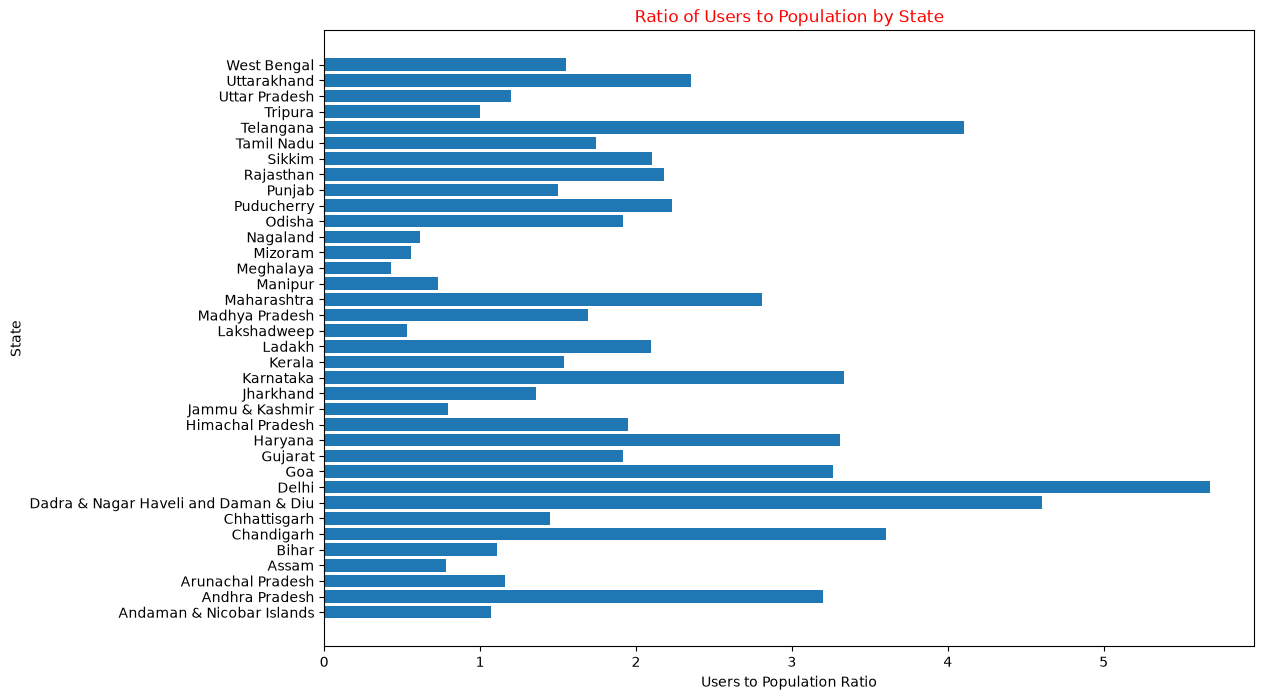

In [75]:
# Column chart -> ratio of users to population by state
plt.figure(figsize=(12, 8))
plt.barh(state_users_population["State"], state_users_population["Users_to_Population_Ratio"])
plt.xlabel("Users to Population Ratio")
plt.ylabel("State")
plt.title("Ratio of Users to Population by State", color= "red")
plt.show()

⚠️ `Registered Users` is a **running total** reported every quarter, so summing it over all quarters counts the same users many times and the ratio comes out too high. A more realistic ratio uses only the **latest quarter**:

In [76]:
latest_year = df_state_txn_users["Year"].max()
latest_q = df_state_txn_users[df_state_txn_users["Year"] == latest_year]["Quarter"].max()

latest_users = df_state_txn_users[(df_state_txn_users["Year"] == latest_year) & (df_state_txn_users["Quarter"] == latest_q)]

state_users_population_latest = pd.merge(latest_users[["State", "Registered Users"]], state_population, on= "State")
state_users_population_latest["Users_to_Population_Ratio"] = (
    state_users_population_latest["Registered Users"] / state_users_population_latest["Population"]
)
state_users_population_latest.sort_values(by= "Users_to_Population_Ratio", ascending= False)

,State,Registered Users,Population,Users_to_Population_Ratio
8,Delhi,11182699,16787941,0.666115
7,Dadra & Nagar Haveli and Daman & Diu,344994,586956,0.587768
31,Telangana,18306880,36366570,0.503399
5,Chandigarh,448572,1055450,0.425005
15,Karnataka,25751023,60965960,0.422384
9,Goa,609106,1457723,0.417848
11,Haryana,10530594,25855357,0.407289
1,Andhra Pradesh,19620905,49378776,0.397355
20,Maharashtra,39664697,112378989,0.352955
33,Uttarakhand,3004040,10116752,0.296937


**Observation (Q13):**
- Summing the running total over all quarters gives ratios **above 1** (more users than people), which is not meaningful.
- Using the latest quarter (2021 Q2): **Delhi (~0.67)**, Dadra & Nagar Haveli and Daman & Diu, **Telangana (~0.50)**, Chandigarh and **Karnataka (~0.42)** have the highest PhonePe penetration.
- **Meghalaya (~0.06)**, Lakshadweep, Mizoram, Nagaland and Jammu & Kashmir have the lowest.
- *Note: population figures are from the census, so the ratios are approximate.*

## 14. Population Density vs Transaction Volume
**Q14.1** Merge the district level transaction data with the district demographics and calculate the correlation between population density and transaction volume.

In [77]:
df_district_txn_users

,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,Nicobars,AN01,528,1.139849e+06,2158.804548,262,0
1,Andaman & Nicobar Islands,2018,1,North And Middle Andaman,AN02,442,9.316631e+05,2107.835016,632,0
2,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,1.256025e+07,2208.201361,5846,0
3,Andaman & Nicobar Islands,2018,2,Nicobars,AN01,1120,3.072437e+06,2743.247239,351,0
4,Andaman & Nicobar Islands,2018,2,North And Middle Andaman,AN02,825,1.317863e+06,1597.409798,911,0
...,...,...,...,...,...,...,...,...,...,...
10243,West Bengal,2021,2,Purba Bardhaman,WB19,3920729,7.572502e+09,1931.401639,787970,12128849
10244,West Bengal,2021,2,Purba Medinipur,WB20,6418522,1.515507e+10,2361.146027,946277,15491958
10245,West Bengal,2021,2,Purulia,WB21,1895981,2.790996e+09,1472.059252,435131,8843358
10246,West Bengal,2021,2,South Twenty Four Parganas,WB22,6661813,1.339853e+10,2011.243709,1286588,19344293


In [78]:
df_district_demographics

,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
0,Andhra Pradesh,Anantapur,Anantapur,4083315,19130.0,213,AP01,Anantapur
1,Andhra Pradesh,Chittoor,Chittoor,4170468,15152.0,275,AP02,Chittoor
2,Andhra Pradesh,East Godavari,Kakinada,5151549,10807.0,477,AP03,East Godavari
3,Andhra Pradesh,Guntur,Guntur,4889230,11391.0,429,AP04,Guntur
4,Andhra Pradesh,YSR,Kadapa,2884524,15359.0,188,AP13,YSR
...,...,...,...,...,...,...,...,...
737,Delhi,West Delhi,Rajouri Garden,2543243,112.0,19563,DL11,West
738,Puducherry,Karaikal,Karaikal,200222,157.0,1275,PY01,Karaikal
739,Puducherry,Mahé,Mahé,41816,9.0,4646,PY02,Mahe
740,Puducherry,Puducherry,Pondicherry,950289,293.0,3232,PY03,Puducherry


In [79]:
district_merged = pd.merge(df_district_txn_users, df_district_demographics, on= ["State", "District", "Code"])

print("Merged district-level dataset:")
district_merged.head()

Merged district-level dataset:


,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens,Headquarters,Population,Area (sq km),Density,Alternate Name
0,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,1.256025e+07,2208.201361,5846,0,Port Blair,238142,2672.0,89,South Andaman
1,Andaman & Nicobar Islands,2018,2,South Andaman,AN03,9395,2.394824e+07,2549.040502,8143,0,Port Blair,238142,2672.0,89,South Andaman
2,Andaman & Nicobar Islands,2018,3,South Andaman,AN03,13511,4.426811e+07,3276.449742,10474,0,Port Blair,238142,2672.0,89,South Andaman
3,Andaman & Nicobar Islands,2018,4,South Andaman,AN03,20136,7.541184e+07,3745.125189,13133,0,Port Blair,238142,2672.0,89,South Andaman
4,Andaman & Nicobar Islands,2019,1,South Andaman,AN03,25683,8.550197e+07,3329.127142,15961,0,Port Blair,238142,2672.0,89,South Andaman


In [80]:
correlation = district_merged[["Density", "Transactions"]].corr()
correlation

,Density,Transactions
Density,1.000000,0.307704
Transactions,0.307704,1.000000


In [81]:
# [0, 1] -> correlation of Density with Transactions
correlation = district_merged[["Density", "Transactions"]].corr().iloc[0, 1]

print(f"Correlation between population density and transaction volume: {correlation}")

Correlation between population density and transaction volume: 0.30770410875592774


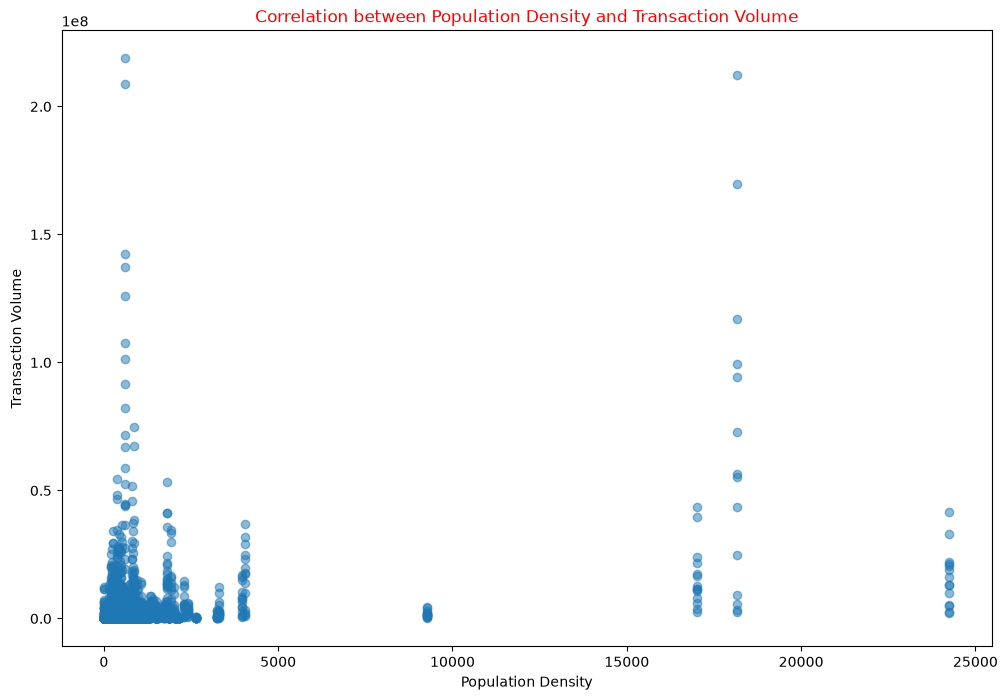

In [82]:
# Scatter plot -> population density vs transaction volume
plt.figure(figsize=(12, 8))
plt.scatter(district_merged["Density"], district_merged["Transactions"], alpha= 0.5)
plt.xlabel("Population Density")
plt.ylabel("Transaction Volume")
plt.title("Correlation between Population Density and Transaction Volume", color= "red")
plt.show()

**Observation (Q14):** The correlation between population density and transaction volume is **~0.31** – a **weak positive** relationship. Denser districts tend to transact a bit more, but density alone does not explain transaction volume (a few very dense urban districts are outliers in the scatter plot).

## 15. Average Transaction Amount per User
**Q15.1** Calculate the average transaction amount per user for each state.

In [83]:
state_transactions = df_state_txn_users.groupby("State").agg({
    "Amount (INR)": "sum",
    "Registered Users": "sum"
}).reset_index()

state_transactions

,State,Amount (INR),Registered Users
0,Andaman & Nicobar Islands,3.641818e+09,408396
1,Andhra Pradesh,3.187847e+12,158007957
2,Arunachal Pradesh,2.225183e+10,1862214
3,Assam,2.814087e+11,26860751
4,Bihar,1.639579e+12,115284760
5,Chandigarh,5.371208e+10,3801466
6,Chhattisgarh,4.156353e+11,37448388
7,Dadra & Nagar Haveli and Daman & Diu,1.865878e+10,2701112
8,Delhi,1.649942e+12,95374654
9,Goa,4.427187e+10,4755320


In [84]:
state_transactions["Avg_Transaction_Amount_Per_User"] = (
    state_transactions["Amount (INR)"] / state_transactions["Registered Users"]
)
print("Average transaction amount per user for each state:")
state_transactions

Average transaction amount per user for each state:


,State,Amount (INR),Registered Users,Avg_Transaction_Amount_Per_User
0,Andaman & Nicobar Islands,3.641818e+09,408396,8917.369075
1,Andhra Pradesh,3.187847e+12,158007957,20175.233763
2,Arunachal Pradesh,2.225183e+10,1862214,11949.126662
3,Assam,2.814087e+11,26860751,10476.576498
4,Bihar,1.639579e+12,115284760,14221.991933
5,Chandigarh,5.371208e+10,3801466,14129.308175
6,Chhattisgarh,4.156353e+11,37448388,11098.884128
7,Dadra & Nagar Haveli and Daman & Diu,1.865878e+10,2701112,6907.815954
8,Delhi,1.649942e+12,95374654,17299.587909
9,Goa,4.427187e+10,4755320,9309.966756


**Q15.2** Identify the top 5 states with the highest and the top 5 states with the lowest average transaction amount per user.

In [85]:
state_avg_txn_amount_sorted = (
    state_transactions.sort_values(by= "Avg_Transaction_Amount_Per_User", ascending= False)
)
top_5_states_highest_avg_txn = state_avg_txn_amount_sorted.head(5)

print("Top 5 states with the highest average transaction amount per user:")
top_5_states_highest_avg_txn

Top 5 states with the highest average transaction amount per user:


,State,Amount (INR),Registered Users,Avg_Transaction_Amount_Per_User
31,Telangana,4.574246e+12,149224214,30653.509622
15,Karnataka,4.361396e+12,203098564,21474.282206
1,Andhra Pradesh,3.187847e+12,158007957,20175.233763
28,Rajasthan,2.625584e+12,149770064,17530.768707
8,Delhi,1.649942e+12,95374654,17299.587909


In [86]:
top_5_states_lowest_avg_txn = state_avg_txn_amount_sorted.tail(5)

print("Top 5 states with the lowest average transaction amount per user:")
top_5_states_lowest_avg_txn

Top 5 states with the lowest average transaction amount per user:


,State,Amount (INR),Registered Users,Avg_Transaction_Amount_Per_User
12,Himachal Pradesh,9.786546e+10,13373980,7317.601442
16,Kerala,3.729599e+11,51267042,7274.846690
7,Dadra & Nagar Haveli and Daman & Diu,1.865878e+10,2701112,6907.815954
32,Tripura,2.097051e+10,3661575,5727.184275
18,Lakshadweep,1.921587e+08,34223,5614.898889


## 16. Device Brand Usage Ratio
**Q16.1** Merge the State_DeviceData dataset with the State_Txn and Users dataset and calculate the ratio of users using each device brand to the total number of registered users in each state.

In [87]:
df_state_device

,State,Year,Quarter,Brand,Registered Users,Percentage
0,Andaman & Nicobar Islands,2018,1,Xiaomi,1665,0.247033
1,Andaman & Nicobar Islands,2018,1,Samsung,1445,0.214392
2,Andaman & Nicobar Islands,2018,1,Vivo,982,0.145697
3,Andaman & Nicobar Islands,2018,1,Oppo,501,0.074332
4,Andaman & Nicobar Islands,2018,1,OnePlus,332,0.049258
...,...,...,...,...,...,...
5539,West Bengal,2021,2,Lenovo,350841,0.019513
5540,West Bengal,2021,2,Asus,297579,0.016551
5541,West Bengal,2021,2,Huawei,272965,0.015182
5542,West Bengal,2021,2,Apple,201393,0.011201


In [88]:
df_state_txn_users

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
0,Andaman & Nicobar Islands,2018,1,6658,1.463176e+07,2197.621091,6740,0
1,Andaman & Nicobar Islands,2018,2,11340,2.833854e+07,2498.989022,9405,0
2,Andaman & Nicobar Islands,2018,3,16265,5.555747e+07,3415.768284,12149,0
3,Andaman & Nicobar Islands,2018,4,23758,9.054834e+07,3811.277720,15222,0
4,Andaman & Nicobar Islands,2019,1,30486,1.022997e+08,3355.630147,18596,0
...,...,...,...,...,...,...,...,...
499,West Bengal,2020,2,57676797,1.000994e+11,1735.523418,13222022,198589332
500,West Bengal,2020,3,79954504,1.568134e+11,1961.282329,14448366,246554831
501,West Bengal,2020,4,100340645,1.991655e+11,1984.893473,15662093,291721919
502,West Bengal,2021,1,118254052,2.429372e+11,2054.366877,16808799,316832674


In [89]:
# Merge on State + Year + Quarter so every brand row gets the total users of the SAME quarter.
# (Merging on State alone would pair each brand row with every quarter's total.)
df_state_txn_users["Year"] = df_state_txn_users["Year"].astype("int64")

state_device_merged = (
    pd.merge(df_state_device, df_state_txn_users[["State", "Year", "Quarter", "Registered Users"]],
    on= ["State", "Year", "Quarter"])
)
print("Merged state-level device data:")
state_device_merged

Merged state-level device data:


,State,Year,Quarter,Brand,Registered Users_x,Percentage,Registered Users_y
0,Andaman & Nicobar Islands,2018,1,Xiaomi,1665,0.247033,6740
1,Andaman & Nicobar Islands,2018,1,Samsung,1445,0.214392,6740
2,Andaman & Nicobar Islands,2018,1,Vivo,982,0.145697,6740
3,Andaman & Nicobar Islands,2018,1,Oppo,501,0.074332,6740
4,Andaman & Nicobar Islands,2018,1,OnePlus,332,0.049258,6740
...,...,...,...,...,...,...,...
5539,West Bengal,2021,2,Lenovo,350841,0.019513,17979979
5540,West Bengal,2021,2,Asus,297579,0.016551,17979979
5541,West Bengal,2021,2,Huawei,272965,0.015182,17979979
5542,West Bengal,2021,2,Apple,201393,0.011201,17979979


In [90]:
# _x -> brand users (device data), _y -> total state users (txn data)
state_device_merged["Brand_Usage_Ratio"] = (
    state_device_merged["Registered Users_x"] / state_device_merged["Registered Users_y"]
)
print("Device brand usage ratio for each state:")
state_device_merged[["State", "Year", "Quarter", "Brand", "Registered Users_x", "Registered Users_y", "Brand_Usage_Ratio"]]

Device brand usage ratio for each state:


,State,Year,Quarter,Brand,Registered Users_x,Registered Users_y,Brand_Usage_Ratio
0,Andaman & Nicobar Islands,2018,1,Xiaomi,1665,6740,0.247033
1,Andaman & Nicobar Islands,2018,1,Samsung,1445,6740,0.214392
2,Andaman & Nicobar Islands,2018,1,Vivo,982,6740,0.145697
3,Andaman & Nicobar Islands,2018,1,Oppo,501,6740,0.074332
4,Andaman & Nicobar Islands,2018,1,OnePlus,332,6740,0.049258
...,...,...,...,...,...,...,...
5539,West Bengal,2021,2,Lenovo,350841,17979979,0.019513
5540,West Bengal,2021,2,Asus,297579,17979979,0.016551
5541,West Bengal,2021,2,Huawei,272965,17979979,0.015182
5542,West Bengal,2021,2,Apple,201393,17979979,0.011201


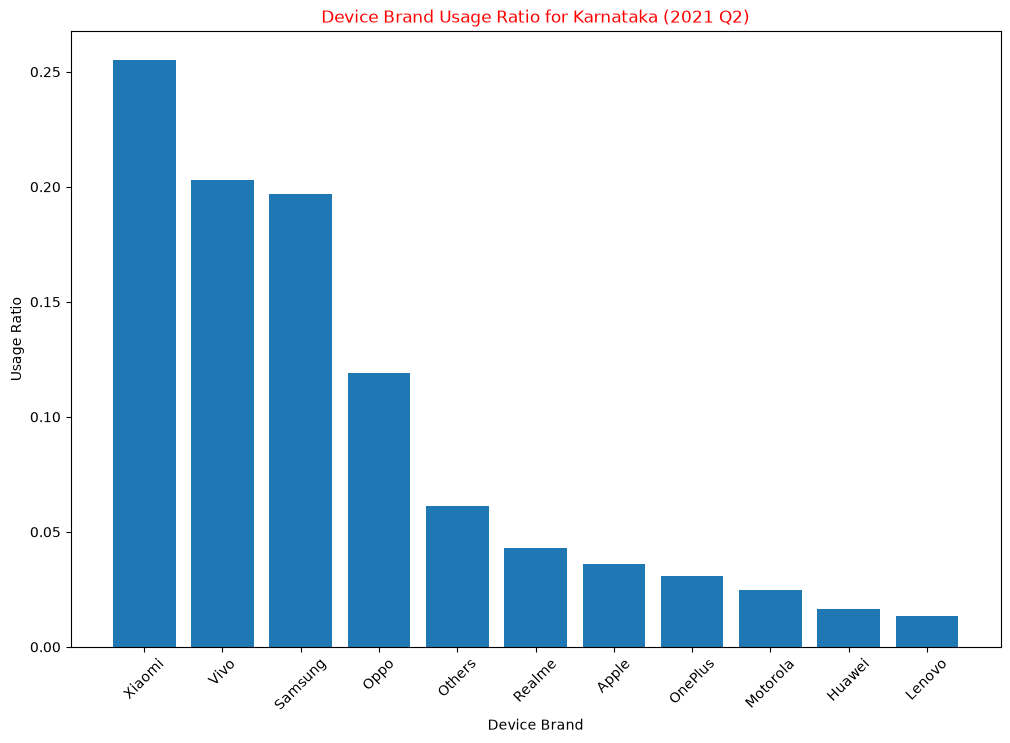

In [91]:
# Bar chart -> device brand usage ratio for a selected state (latest quarter in device data)
selected_state = "Karnataka"

state_data = state_device_merged[state_device_merged["State"] == selected_state]
state_data = state_data[(state_data["Year"] == state_data["Year"].max())]
state_data = state_data[state_data["Quarter"] == state_data["Quarter"].max()].sort_values(by= "Brand_Usage_Ratio", ascending= False)

plt.figure(figsize=(12, 8))
plt.bar(state_data["Brand"], state_data["Brand_Usage_Ratio"])
plt.xlabel("Device Brand")
plt.ylabel("Usage Ratio")
plt.title(f"Device Brand Usage Ratio for {selected_state} ({state_data['Year'].iloc[0]} Q{state_data['Quarter'].iloc[0]})", color= "red")
plt.xticks(rotation=45)
plt.show()

## 17. Visualizations
**Q17.1** Create a line plot showing the total number of transactions over time (years and quarters) for a selected state.

In [92]:
selected_state = "Karnataka"

# Filter data for the selected state
state_data = df_state_txn_users[df_state_txn_users["State"] == selected_state].copy()
state_data

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens
210,Karnataka,2018,1,12016899,1.921790e+10,1599.239148,3717763,0
211,Karnataka,2018,2,17116447,3.351558e+10,1958.092125,5030665,0
212,Karnataka,2018,3,25980261,4.822509e+10,1856.220450,6372649,0
213,Karnataka,2018,4,44812071,7.300839e+10,1629.212508,8315802,0
214,Karnataka,2019,1,86587609,1.179764e+11,1362.508834,10266174,0
215,Karnataka,2019,2,115401604,1.637020e+11,1418.542018,11968087,113024811
216,Karnataka,2019,3,170733735,2.145367e+11,1256.557296,13635075,445683660
217,Karnataka,2019,4,237796252,2.950471e+11,1240.756071,15385416,569674870
218,Karnataka,2020,1,271033890,3.534021e+11,1303.903563,17016980,626488036
219,Karnataka,2020,2,213221712,3.211049e+11,1505.967071,18655366,490510075


In [93]:
# New column combining Year and Quarter for plotting
state_data["Year_Quarter"] = (
    state_data["Year"].astype(str)
    + " Q" +
    state_data["Quarter"].astype(str)
)

state_data

,State,Year,Quarter,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens,Year_Quarter
210,Karnataka,2018,1,12016899,1.921790e+10,1599.239148,3717763,0,2018 Q1
211,Karnataka,2018,2,17116447,3.351558e+10,1958.092125,5030665,0,2018 Q2
212,Karnataka,2018,3,25980261,4.822509e+10,1856.220450,6372649,0,2018 Q3
213,Karnataka,2018,4,44812071,7.300839e+10,1629.212508,8315802,0,2018 Q4
214,Karnataka,2019,1,86587609,1.179764e+11,1362.508834,10266174,0,2019 Q1
215,Karnataka,2019,2,115401604,1.637020e+11,1418.542018,11968087,113024811,2019 Q2
216,Karnataka,2019,3,170733735,2.145367e+11,1256.557296,13635075,445683660,2019 Q3
217,Karnataka,2019,4,237796252,2.950471e+11,1240.756071,15385416,569674870,2019 Q4
218,Karnataka,2020,1,271033890,3.534021e+11,1303.903563,17016980,626488036,2020 Q1
219,Karnataka,2020,2,213221712,3.211049e+11,1505.967071,18655366,490510075,2020 Q2


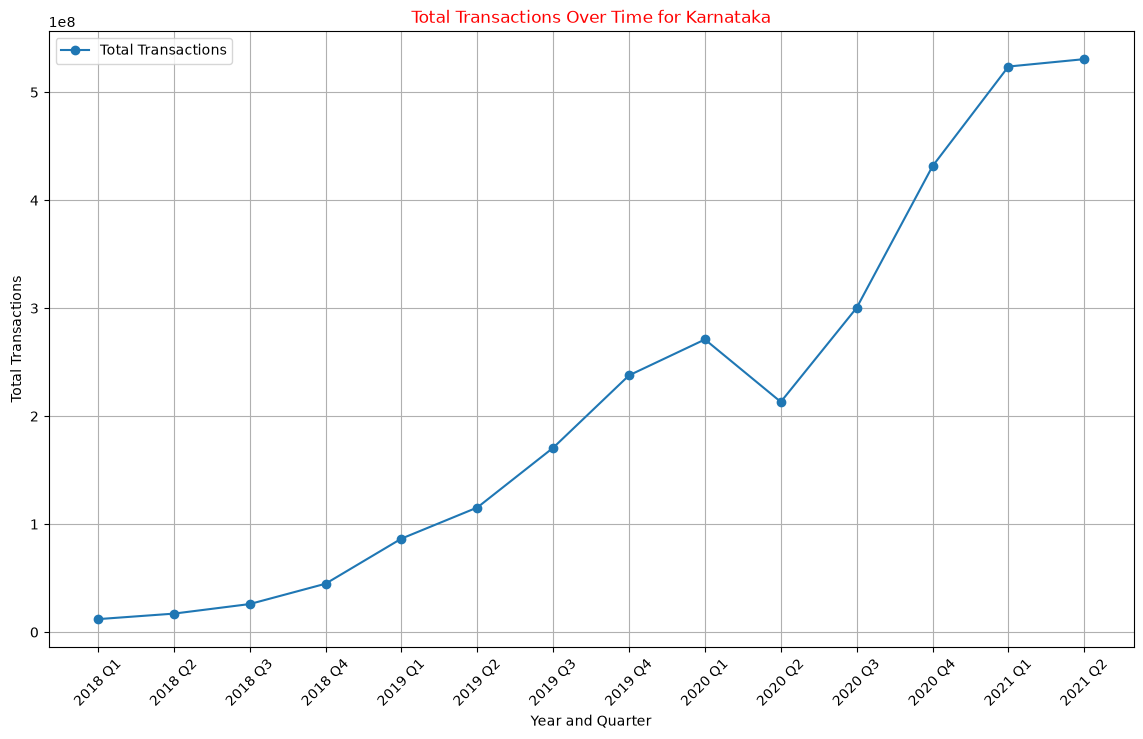

In [94]:
# Plot total transactions over time
plt.figure(figsize=(14, 8))
plt.plot(state_data["Year_Quarter"], state_data["Transactions"], marker= "o", label= "Total Transactions")
plt.xlabel("Year and Quarter")
plt.ylabel("Total Transactions")
plt.title(f"Total Transactions Over Time for {selected_state}", color= "red")
plt.xticks(rotation=45)
plt.legend()
plt.grid(True)
plt.show()

**Q17.2** Create a pie chart showing the distribution of transaction types for a specific state and quarter.

In [95]:
selected_state = "Ladakh"
selected_year = 2021
selected_quarter = 1

# Filter data for the selected state, year, and quarter
state_quarter_data = df_state_txn_split[(df_state_txn_split["State"] == selected_state) &
                                        (df_state_txn_split["Year"] == selected_year) &
                                        (df_state_txn_split["Quarter"] == selected_quarter)]

state_quarter_data

,State,Year,Quarter,Transaction Type,Transactions,Amount (INR),ATV (INR)
1250,Ladakh,2021,1,Peer-to-peer payments,141894,8.699998e+08,6131.335970
1251,Ladakh,2021,1,Recharge & bill payments,72719,3.545953e+07,487.624038
1252,Ladakh,2021,1,Merchant payments,58875,7.497791e+07,1273.510208
1253,Ladakh,2021,1,Financial Services,629,1.455016e+06,2313.221221
1254,Ladakh,2021,1,Others,1298,1.527565e+06,1176.860603


In [96]:
# Aggregate transaction types for the selected state and quarter
txn_type_distribution = state_quarter_data.groupby("Transaction Type").agg({
    "Transactions": "sum"
}).reset_index()

txn_type_distribution

,Transaction Type,Transactions
0,Financial Services,629
1,Merchant payments,58875
2,Others,1298
3,Peer-to-peer payments,141894
4,Recharge & bill payments,72719


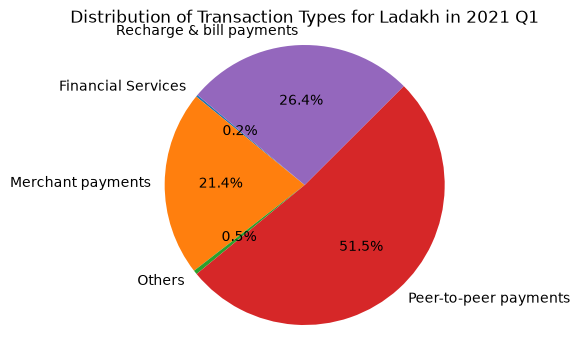

In [97]:
plt.figure(figsize=(6, 4))
plt.pie(txn_type_distribution["Transactions"], labels= txn_type_distribution["Transaction Type"], autopct= "%1.1f%%", startangle= 140)
plt.title(f"Distribution of Transaction Types for {selected_state} in {selected_year} Q{selected_quarter}")
plt.axis("equal")
plt.show()

**Q17.3** Visualize the population density of districts in a selected state using a bar plot.

In [98]:
selected_state = "Punjab"

# Filter data for the selected state
state_population_density = df_district_demographics[df_district_demographics["State"] == selected_state]

state_population_density

,State,District,Headquarters,Population,Area (sq km),Density,Code,Alternate Name
447,Punjab,Amritsar,Amritsar,2490891,2673.0,932,PB01,Amritsar
448,Punjab,Barnala,Barnala,596294,1423.0,419,PB02,Barnala
449,Punjab,Bathinda,Bathinda,1388859,3355.0,414,PB03,Bathinda
450,Punjab,Firozpur,Firozpur,2026831,5334.0,380,PB07,Firozepur
451,Punjab,Faridkot,Faridkot,618008,1472.0,424,PB04,Faridkot
452,Punjab,Fatehgarh Sahib,Fatehgarh Sahib,599814,1180.0,508,PB05,Fatehgarh Sahib
453,Punjab,Fazilka,Fazilka,1180483,3113.0,379,PB06,Fazilka
454,Punjab,Gurdaspur,Gurdaspur,2299026,3542.0,649,PB08,Gurdaspur
455,Punjab,Hoshiarpur,Hoshiarpur,1582793,3397.0,466,PB09,Hoshiarpur
456,Punjab,Jalandhar,Jalandhar,2181753,2625.0,831,PB10,Jalandhar


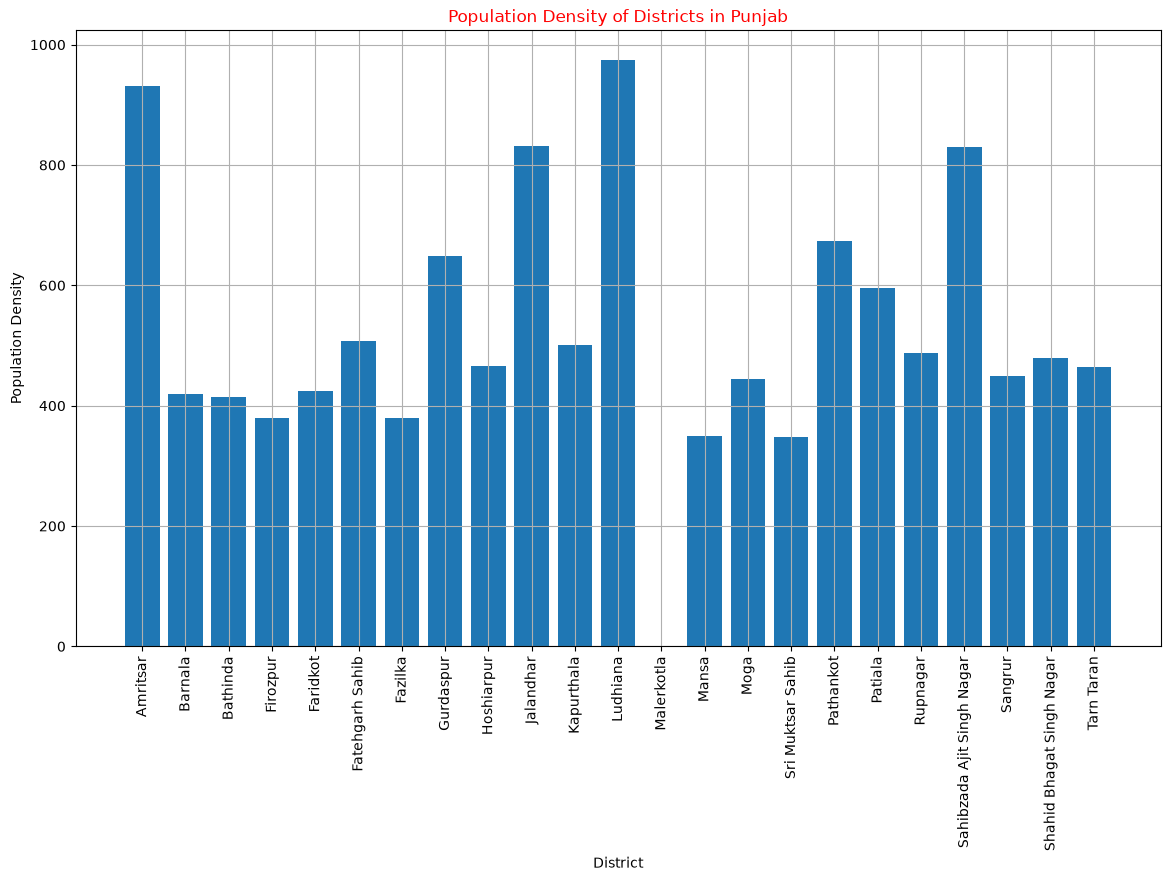

In [99]:
plt.figure(figsize=(14, 8))
plt.bar(state_population_density["District"], state_population_density["Density"])
plt.xlabel("District")
plt.ylabel("Population Density")
plt.title(f"Population Density of Districts in {selected_state}", color= "red")
plt.xticks(rotation=90)
plt.grid(True)
plt.show()

## 18. Trends and Correlations
**Q18.1** Analyze the transaction data to identify trends or patterns – total transactions and total transaction amount over the years for all states.

In [100]:
transaction_trends = df_state_txn_users.groupby(["Year"]).agg({
    "Transactions": "sum",
    "Amount (INR)": "sum"
}).reset_index()

print("Transaction trends over the years:")
transaction_trends

Transaction trends over the years:


,Year,Transactions,Amount (INR)
0,2018,1080202410,1.623045e+12
1,2019,4079827215,6.276688e+12
2,2020,7973974741,1.464116e+13
3,2021,7398955928,1.308826e+13


In [101]:
# Summarize findings
transaction_trends_summary = transaction_trends.describe()
print("Summary of transaction trends:")
transaction_trends_summary

Summary of transaction trends:


,Year,Transactions,Amount (INR)
count,4.000000,4.000000e+00,4.000000e+00
mean,2019.500000,5.133240e+09,8.907290e+12
std,1.290994,3.201043e+09,6.064600e+12
min,2018.000000,1.080202e+09,1.623045e+12
25%,2018.750000,3.329921e+09,5.113277e+12
50%,2019.500000,5.739392e+09,9.682476e+12
75%,2020.250000,7.542711e+09,1.347649e+13
max,2021.000000,7.973975e+09,1.464116e+13


**Observation (Q18.1):**

| Year | Transactions | Amount (₹ lakh crore) |
|---|---|---|
| 2018 | ~108 crore | ~1.6 |
| 2019 | ~408 crore | ~6.3 |
| 2020 | ~797 crore | ~14.6 |
| 2021 (Q1–Q2 only) | ~740 crore | ~13.1 |

Transactions grew ~4× from 2018 to 2019 and ~2× from 2019 to 2020. **2021 has only 2 quarters** but has already almost matched the whole of 2020, so growth is continuing strongly.

**Q18.2** Find correlations between demographic data (e.g., population density) and transaction data (e.g., transaction volume). Summarize your findings. [Hint: you can use `corr()`]

In [102]:
# Merge district transaction data with demographic data
merged_data = pd.merge(df_district_txn_users, df_district_demographics, on= ["State", "District", "Code"])

merged_data

,State,Year,Quarter,District,Code,Transactions,Amount (INR),ATV (INR),Registered Users,App Opens,Headquarters,Population,Area (sq km),Density,Alternate Name
0,Andaman & Nicobar Islands,2018,1,South Andaman,AN03,5688,1.256025e+07,2208.201361,5846,0,Port Blair,238142,2672.0,89,South Andaman
1,Andaman & Nicobar Islands,2018,2,South Andaman,AN03,9395,2.394824e+07,2549.040502,8143,0,Port Blair,238142,2672.0,89,South Andaman
2,Andaman & Nicobar Islands,2018,3,South Andaman,AN03,13511,4.426811e+07,3276.449742,10474,0,Port Blair,238142,2672.0,89,South Andaman
3,Andaman & Nicobar Islands,2018,4,South Andaman,AN03,20136,7.541184e+07,3745.125189,13133,0,Port Blair,238142,2672.0,89,South Andaman
4,Andaman & Nicobar Islands,2019,1,South Andaman,AN03,25683,8.550197e+07,3329.127142,15961,0,Port Blair,238142,2672.0,89,South Andaman
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8787,West Bengal,2021,2,Paschim Medinipur,WB18,5051834,1.030351e+10,2039.558976,856640,16201033,Midnapore,4776909,6308.0,757,Paschim Medinipur
8788,West Bengal,2021,2,Purba Bardhaman,WB19,3920729,7.572502e+09,1931.401639,787970,12128849,Bardhaman,4835532,5433.0,890,Purba Bardhaman
8789,West Bengal,2021,2,Purba Medinipur,WB20,6418522,1.515507e+10,2361.146027,946277,15491958,Tamluk,5095875,4736.0,1076,Purba Medinipur
8790,West Bengal,2021,2,Purulia,WB21,1895981,2.790996e+09,1472.059252,435131,8843358,Purulia,2927965,6259.0,468,Purulia


In [103]:
correlation_matrix = merged_data[["Population", "Density", "Transactions", "Amount (INR)", "Registered Users"]].corr()

print("Correlation matrix:")
correlation_matrix

Correlation matrix:


,Population,Density,Transactions,Amount (INR),Registered Users
Population,1.000000,0.304296,0.359157,0.350666,0.657427
Density,0.304296,1.000000,0.307704,0.336795,0.301424
Transactions,0.359157,0.307704,1.000000,0.976292,0.802563
Amount (INR),0.350666,0.336795,0.976292,1.000000,0.783425
Registered Users,0.657427,0.301424,0.802563,0.783425,1.000000


In [104]:
# Summarize findings
correlation_summary = correlation_matrix.describe()
print("Summary of correlation findings:")
correlation_summary

Summary of correlation findings:


,Population,Density,Transactions,Amount (INR),Registered Users
count,5.000000,5.000000,5.000000,5.000000,5.000000
mean,0.534309,0.450044,0.689143,0.689435,0.708968
std,0.295523,0.307761,0.334042,0.326608,0.258724
min,0.304296,0.301424,0.307704,0.336795,0.301424
25%,0.350666,0.304296,0.359157,0.350666,0.657427
50%,0.359157,0.307704,0.802563,0.783425,0.783425
75%,0.657427,0.336795,0.976292,0.976292,0.802563
max,1.000000,1.000000,1.000000,1.000000,1.000000


**Observation (Q18.2):**
- **Transactions ↔ Amount (~0.98):** almost perfectly correlated – more transactions means more money moved.
- **Registered Users ↔ Transactions (~0.80):** strong – more users drive more transactions.
- **Population ↔ Registered Users (~0.66):** moderate – bigger districts have more users.
- **Population / Density ↔ Transactions (~0.31–0.36):** weak – demographics alone are not a strong predictor; urbanisation, income and internet access matter more.